# Revised regional clustering analysis

This is the corrected version of `Stunting_Clustering_Analysis.ipynb`. The original notebook and Excel workbook are preserved.

Four regional rate indicators are summarized as unweighted means of available district observations within each of 34 historical provinces. These summaries are **not population-weighted provincial prevalence estimates**. The count previously called `Total_Births` is excluded because the source column is a stunted-child count, not births.

K-Means silhouette over k=2–8 selects the common number of groups. All three algorithms retain the constructor settings used in the original notebook except for the selected number of groups. Group names are descriptive and have no validated clinical-risk meaning. Run all cells from the repository root.

In [1]:
from datetime import datetime, timezone
import hashlib
import json
from pathlib import Path
import platform

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display, Image
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from threadpoolctl import threadpool_limits
from analysis.revision.clustering import read_district_indicators, aggregate_profiles, neutral_labels, FEATURES

ROOT = Path.cwd()
SOURCE = ROOT / "dataset/Data-Status-Gizi-2018-2020-Kabupaten-Kota.xlsx"
ORIGINAL_NOTEBOOK = ROOT / "Stunting_Clustering_Analysis.ipynb"
OUT = ROOT / "results/clustering_revised"
OUT.mkdir(parents=True, exist_ok=True)
source_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in [SOURCE, ORIGINAL_NOTEBOOK]}
matplotlib.rcParams["figure.dpi"] = 500
matplotlib.rcParams["font.family"] = "serif"
matplotlib.rcParams["font.serif"] = ["Times New Roman"] + matplotlib.rcParams["font.serif"]
sns.set_theme(style="whitegrid")
matplotlib.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})

## 1. Corrected data preparation

Use the verified stunting, maternal KEK, immunization, and low-birth-weight rate columns. KEK, immunization, and BBLR source fractions are converted to percentages. The immunization source header refers to ages 12–23 months.

For each indicator, average the observed district values within each province and retain its coverage. No provincial imputation is required: every province has observed values for each indicator. Standardization is applied to the four province summaries before clustering.

In [2]:
districts = read_district_indicators(SOURCE)
profiles, coverage = aggregate_profiles(districts)
assert len(districts) == 514 and len(profiles) == 34
assert np.isfinite(profiles[FEATURES].to_numpy()).all()
scaler = StandardScaler()
scaled = scaler.fit_transform(profiles[FEATURES])
print(f"District observations: {len(districts)}; historical provinces: {len(profiles)}")
print("Missing district observations by indicator:")
display(districts[FEATURES].isna().sum().rename("Missing"))
display(profiles.head())

District observations: 514; historical provinces: 34
Missing district observations by indicator:


Stunting_2019     0
KEK              61
Immunization     11
BBLR             40
Name: Missing, dtype: int64

,Province,Stunting_2019,KEK,Immunization,BBLR
0,Aceh,33.504348,12.306009,24.219049,6.475239
1,Bali,15.100000,14.256298,90.927782,6.196608
2,Bangka Belitung,19.757143,15.428833,75.012584,6.010139
3,Banten,26.125000,19.511413,45.385546,5.469216
4,Bengkulu,26.090000,15.037300,62.029176,5.306426


## 2. Selection of the common number of groups

Evaluate K-Means at k=2–8 with the original constructor settings. Select the maximum silhouette, preferring smaller k in an exact tie. WSS is displayed as a diagnostic. This rule does not establish the optimal k for every algorithm or clinical validity of the groups.

In [3]:
selection_rows = []
with threadpool_limits(limits=1):
    for k in range(2, 9):
        candidate = KMeans(n_clusters=k, random_state=42)
        labels = candidate.fit_predict(scaled)
        selection_rows.append({"k": k, "WSS": float(candidate.inertia_),
                               "Silhouette": float(silhouette_score(scaled, labels))})
selection = pd.DataFrame(selection_rows)
selected_k = int(selection.sort_values(["Silhouette", "k"], ascending=[False, True]).iloc[0]["k"])
print("Selected number of groups:", selected_k)
display(selection)

Selected number of groups: 2


,k,WSS,Silhouette
0,2,88.770709,0.280043
1,3,62.920663,0.258593
2,4,56.299926,0.189991
3,5,45.504370,0.213474
4,6,40.014075,0.213510
5,7,37.932664,0.199042
6,8,32.809011,0.222005


## 3. Comparison of the original three algorithms

Use K-Means and GMM with random state 42, and Ward hierarchical clustering. Initialization and other defaults are not increased from the original constructors; resolved settings and library versions are recorded in the output summary.

Group identifiers are relabeled independently for each algorithm by increasing mean stunting indicator. Group 1 and Group 2 are descriptive names, not low/high clinical-risk categories.

In [4]:
models = {
    "K-Means": KMeans(n_clusters=selected_k, random_state=42),
    "GMM": GaussianMixture(n_components=selected_k, random_state=42),
    "Hierarchical": AgglomerativeClustering(n_clusters=selected_k, linkage="ward"),
}
group_columns = {"K-Means": "Group_KMeans", "GMM": "Group_GMM", "Hierarchical": "Group_Hierarchical"}
assignments, metric_rows = {}, []
with threadpool_limits(limits=1):
    for name, model in models.items():
        raw_labels = model.fit_predict(scaled)
        if name == "GMM" and not model.converged_:
            raise RuntimeError("GMM did not converge with the original settings")
        labels = neutral_labels(profiles, raw_labels) + 1
        assignments[name] = labels
        profiles[group_columns[name]] = labels
        metric_rows.append({"Algorithm": name, "Silhouette": float(silhouette_score(scaled, labels)),
                            "DBI": float(davies_bouldin_score(scaled, labels)),
                            "CHI": float(calinski_harabasz_score(scaled, labels))})
metrics = pd.DataFrame(metric_rows)
print("Higher Silhouette/CHI and lower DBI indicate better relative internal scores.")
display(metrics.round(4))

profile_rows = []
for name, labels in assignments.items():
    for group in sorted(np.unique(labels)):
        subset = profiles.loc[labels == group]
        profile_rows.append({"Algorithm": name, "Group": f"Group {group}", "Provinces": len(subset),
                             **{f: float(subset[f].mean()) for f in FEATURES},
                             "Members": " | ".join(subset.Province)})
group_profiles = pd.DataFrame(profile_rows)
print("Group profiles are equal-province averages of district-indicator means (%).")
display(group_profiles.drop(columns="Members").round(2))

pairs = [("K-Means", "GMM"), ("K-Means", "Hierarchical"), ("GMM", "Hierarchical")]
ari = pd.DataFrame([{"Algorithm A": a, "Algorithm B": b,
                     "ARI": float(adjusted_rand_score(assignments[a], assignments[b]))} for a, b in pairs])
display(ari)

Higher Silhouette/CHI and lower DBI indicate better relative internal scores.
Group profiles are equal-province averages of district-indicator means (%).


,Algorithm,Silhouette,DBI,CHI
0,K-Means,0.2800,1.2066,17.0252
1,GMM,0.3464,1.1307,18.9593
2,Hierarchical,0.3852,0.9358,17.2035


,Algorithm,Group,Provinces,Stunting_2019,KEK,Immunization,BBLR
0,K-Means,Group 1,15,23.11,17.27,70.46,6.05
1,K-Means,Group 2,19,31.65,22.51,44.33,7.22
2,GMM,Group 1,24,25.66,17.01,60.85,5.99
3,GMM,Group 2,10,33.21,27.85,43.88,8.42
4,Hierarchical,Group 1,28,26.79,17.25,59.53,6.30
5,Hierarchical,Group 2,6,32.98,33.94,38.74,8.57


,Algorithm A,Algorithm B,ARI
0,K-Means,GMM,0.199715
1,K-Means,Hierarchical,0.032960
2,GMM,Hierarchical,0.545896


## 4. Figures for review

The k-selection figure and three-panel regional scatterplot use the original notebook's plotting style: Seaborn whitegrid, the same font setup, figure sizes (10 × 5 and 18 × 5 inches), line and marker settings, panel titles, and 500 DPI PNG export. The scatterplot retains the Set1 palette and marker size 100.

Only the plotted data, descriptive group labels, and corrected indicator labels change. Axes show district-indicator means rather than population-weighted provincial prevalences. The figures replace the corresponding old clustering figures after author review.

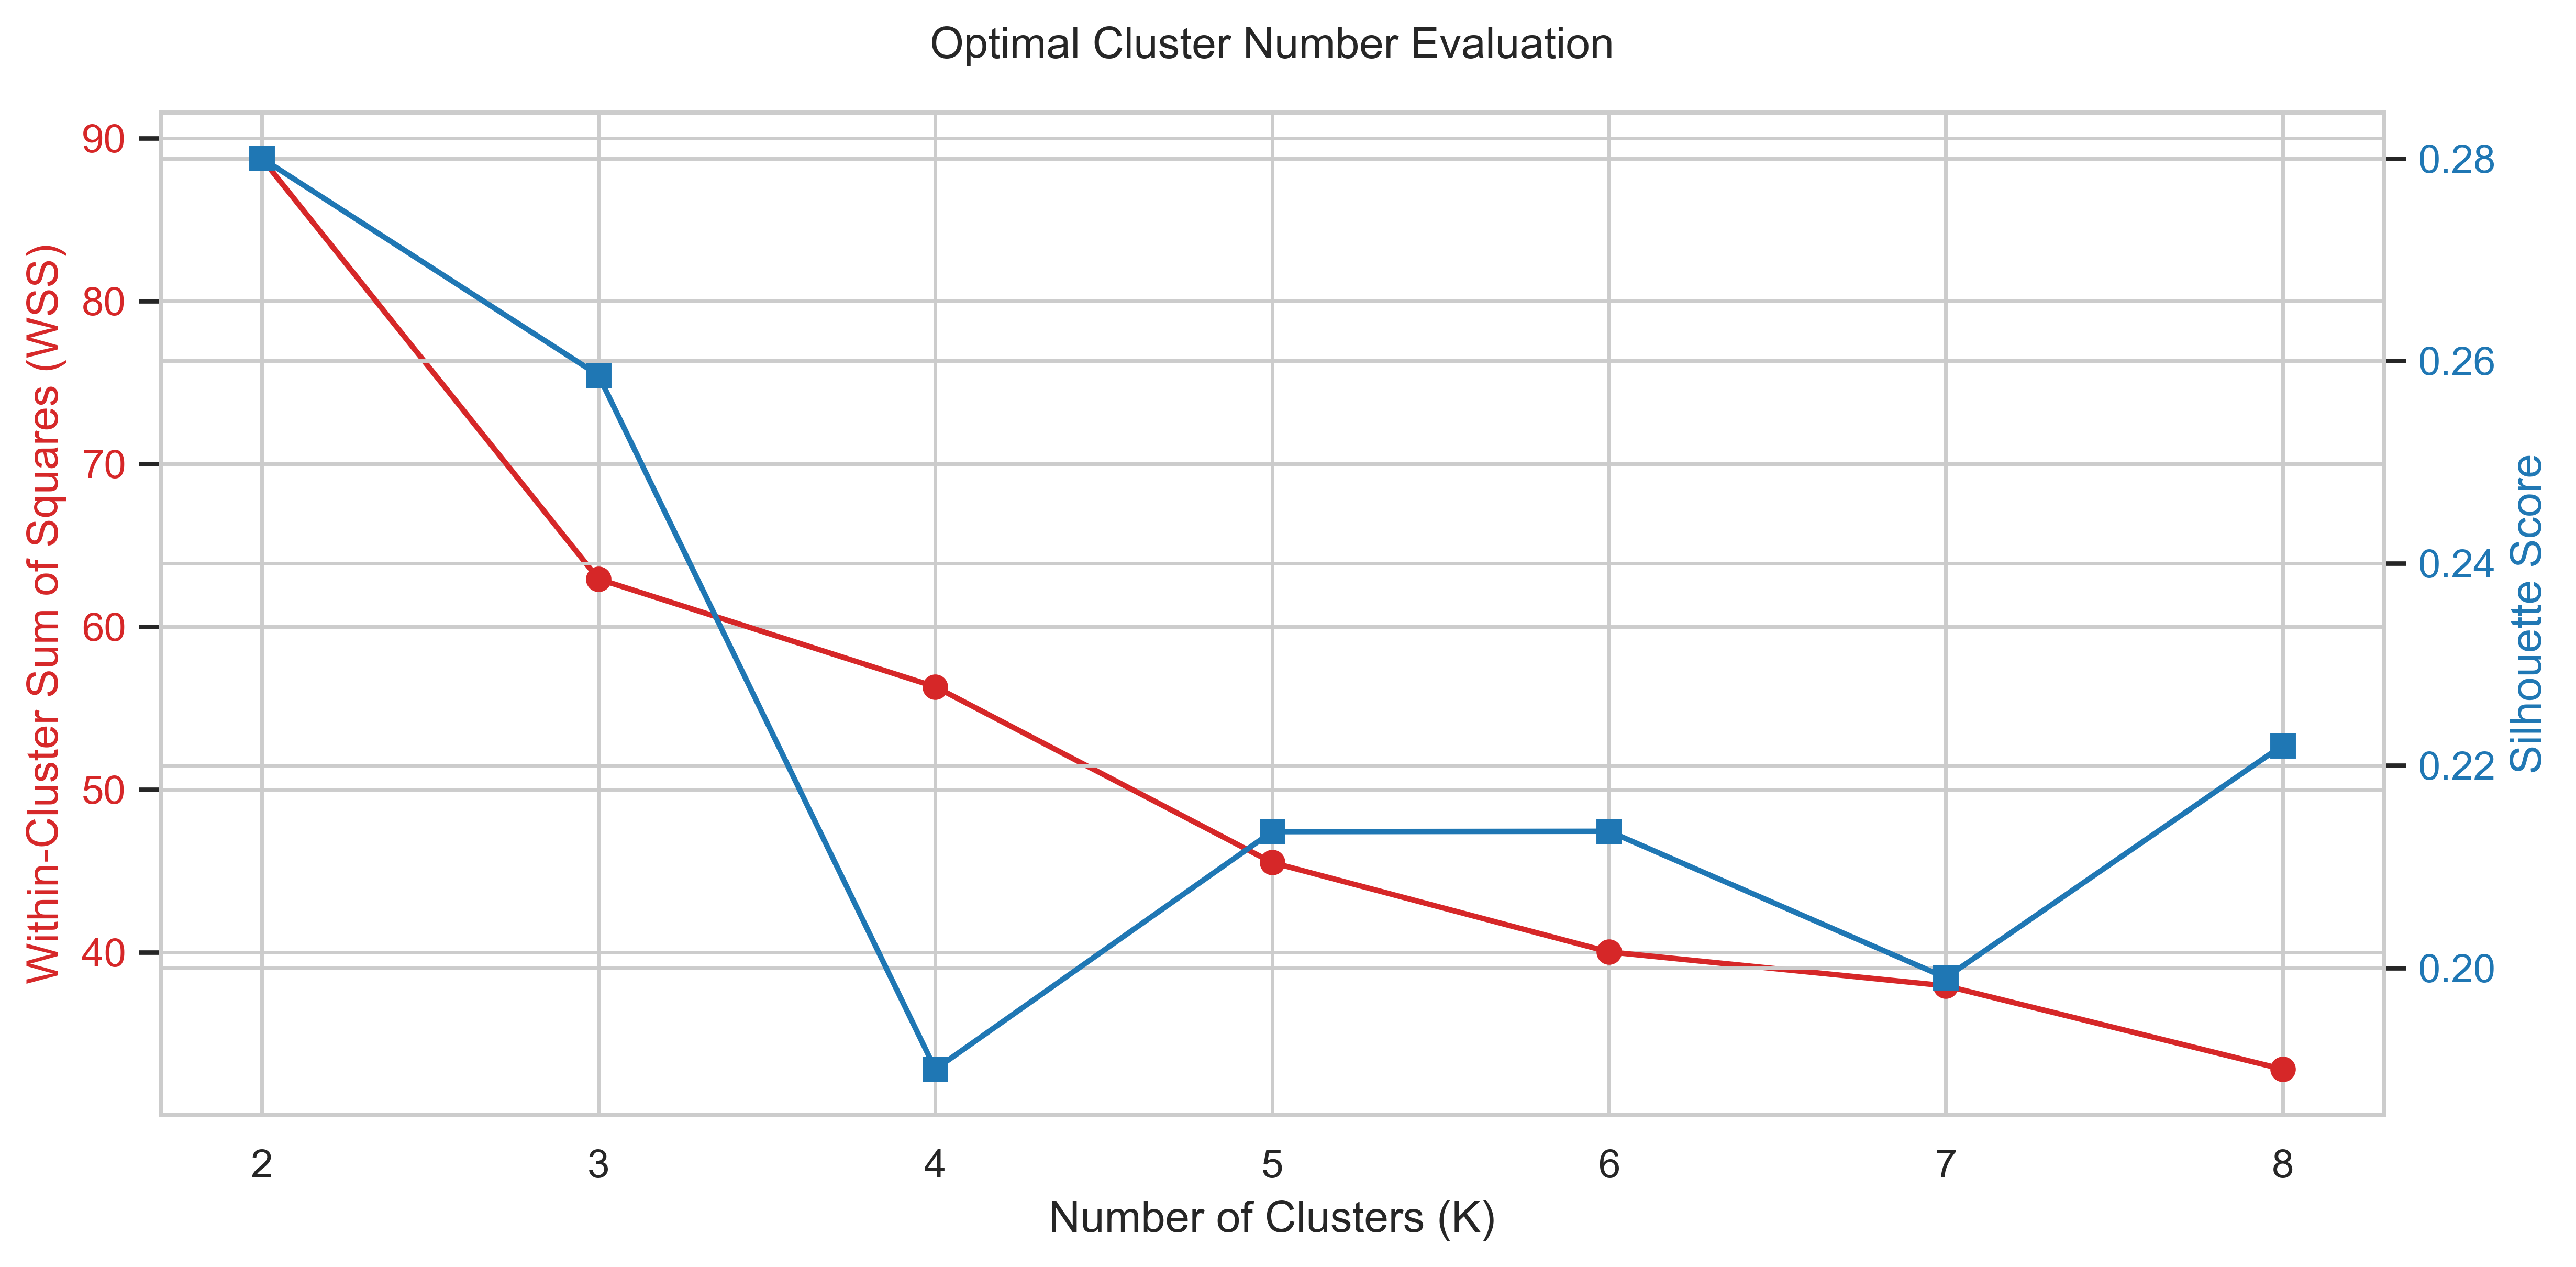

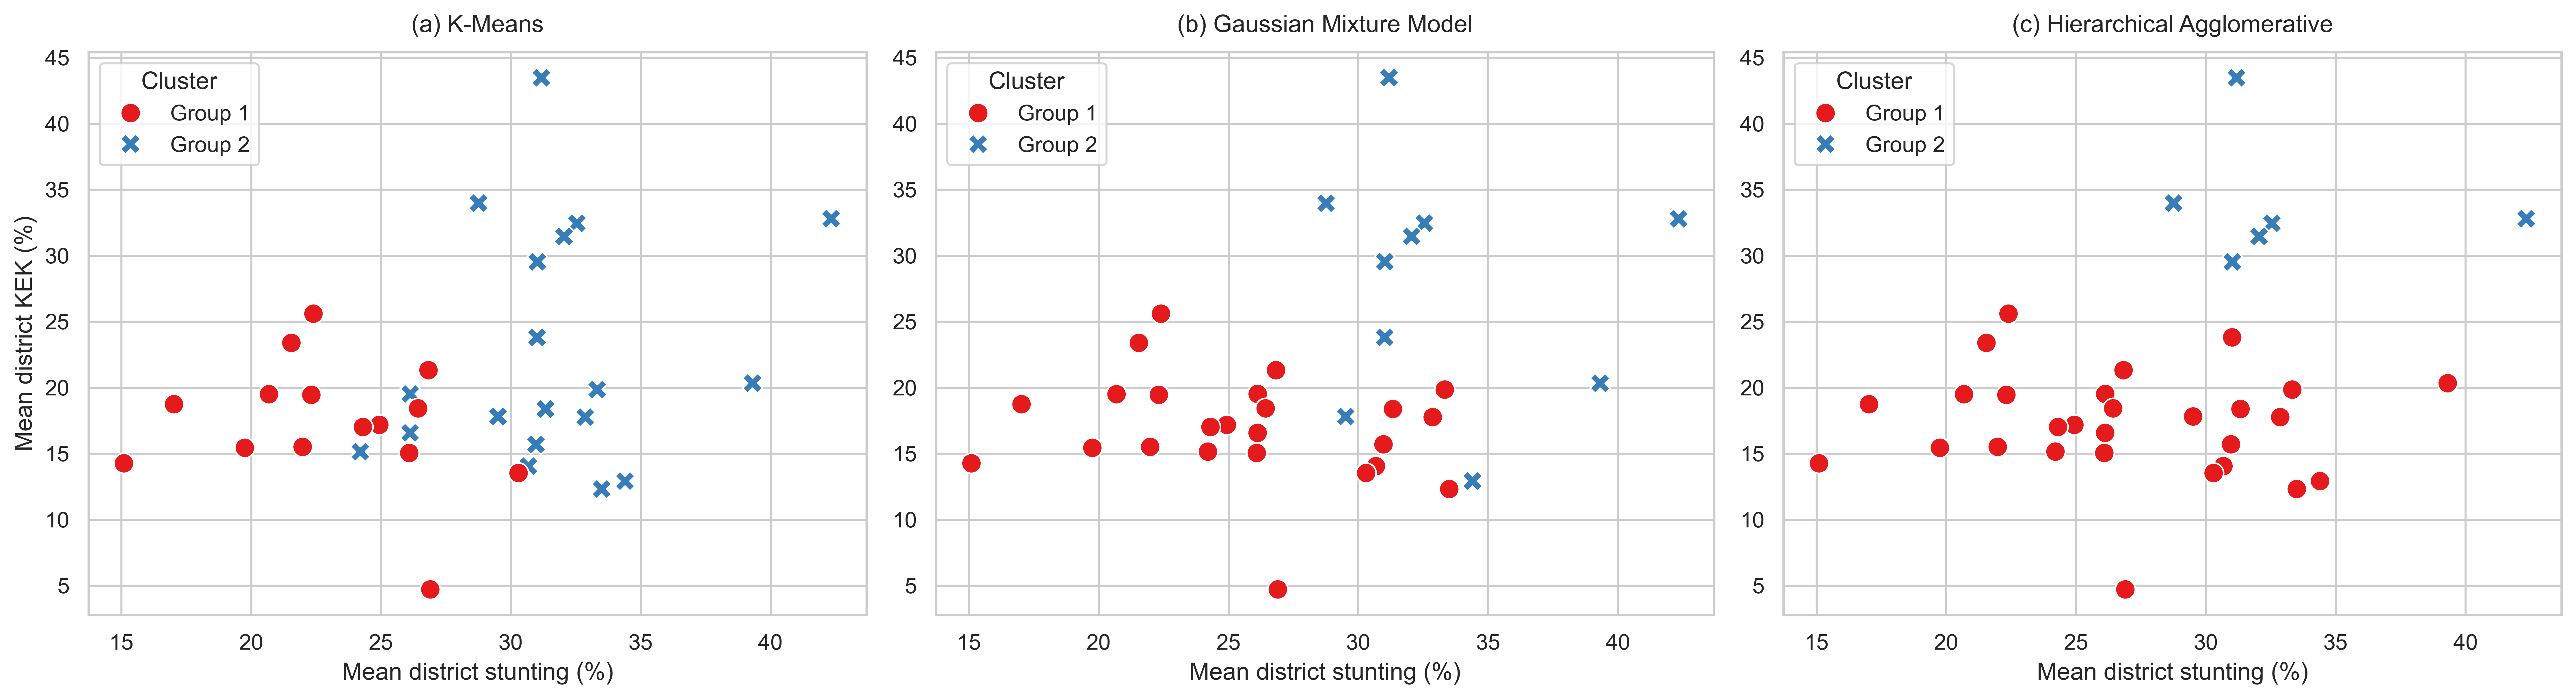

In [5]:
selection_figure, left = plt.subplots(figsize=(10, 5))
left.set_xlabel("Number of Clusters (K)")
left.set_ylabel("Within-Cluster Sum of Squares (WSS)", color="tab:red")
left.plot(selection.k, selection.WSS, "o-", color="tab:red", label="WSS")
left.tick_params(axis="y", labelcolor="tab:red")

right = left.twinx()
right.set_ylabel("Silhouette Score", color="tab:blue")
right.plot(selection.k, selection.Silhouette, "s-", color="tab:blue", label="Silhouette")
right.tick_params(axis="y", labelcolor="tab:blue")
right.set_title("Optimal Cluster Number Evaluation", fontsize=12, pad=15)
selection_figure.tight_layout()
for extension in ["png", "pdf"]:
    selection_figure.savefig(OUT / f"k_selection.{extension}", dpi=500, bbox_inches="tight")
plt.close(selection_figure)
display(Image(filename=str(OUT / "k_selection.png")))

plot_profiles = profiles.copy()
group_order = [f"Group {group}" for group in range(1, selected_k + 1)]
for column in group_columns.values():
    plot_profiles[column] = profiles[column].map(lambda group: f"Group {group}")

regional_figure, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=500)
panel_titles = ["(a) K-Means", "(b) Gaussian Mixture Model", "(c) Hierarchical Agglomerative"]
for ax, column, title in zip(axes, group_columns.values(), panel_titles):
    sns.scatterplot(
        data=plot_profiles, x="Stunting_2019", y="KEK",
        hue=column, style=column, palette="Set1", s=100,
        hue_order=group_order, style_order=group_order, ax=ax,
    )
    ax.set_title(title, fontsize=12, pad=10)
    ax.set_xlabel("Mean district stunting (%)")
    ax.set_ylabel("")
    ax.legend(title="Cluster", loc="upper left")
axes[0].set_ylabel("Mean district KEK (%)")
regional_figure.tight_layout()
for extension in ["png", "pdf"]:
    regional_figure.savefig(OUT / f"regional_profiles.{extension}", dpi=500, bbox_inches="tight")
plt.close(regional_figure)
display(Image(filename=str(OUT / "regional_profiles.png")))

## 5. Save results and provenance

All outputs are written to `results/clustering_revised/`. Historical outputs and the original notebook remain unchanged. Model rankings are reported separately for each metric. Internal scores describe these 34 profiles; they do not validate clinical-risk categories or intervention effectiveness.

In [6]:
for filename, frame in {
    "district_indicators.csv": districts, "coverage.csv": coverage,
    "province_profiles.csv": profiles, "k_selection.csv": selection,
    "metrics.csv": metrics, "group_profiles.csv": group_profiles,
    "algorithm_agreement.csv": ari,
}.items():
    frame.to_csv(OUT / filename, index=False)

summary = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_notebook": "Stunting_Clustering_Analysis.ipynb",
    "revised_notebook": "Stunting_Clustering_Analysis_Revised.ipynb",
    "source_hashes": source_hashes,
    "districts": len(districts), "provinces": len(profiles), "features": FEATURES,
    "feature_units": "percent", "district_missing": districts[FEATURES].isna().sum().to_dict(),
    "aggregation": "Unweighted available-case district-indicator means within each historical province",
    "interpretation": "Descriptive provincial profiles; not population-weighted prevalence or validated clinical-risk categories",
    "province_imputation": "none; each province has observed values for every indicator",
    "selected_k": selected_k,
    "selection_rule": "Maximum K-Means silhouette over k=2..8; lower k breaks exact ties",
    "constructor_policy": "Original notebook constructor settings retained except for selected number of groups; implicit defaults depend on recorded software version",
    "models": {name: {"parameters": model.get_params(),
                      "group_sizes": {f"Group {int(g)}": int((assignments[name] == g).sum())
                                      for g in sorted(np.unique(assignments[name]))}}
               for name, model in models.items()},
    "metric_winners": {"highest_silhouette": metrics.loc[metrics.Silhouette.idxmax(), "Algorithm"],
                       "lowest_dbi": metrics.loc[metrics.DBI.idxmin(), "Algorithm"],
                       "highest_chi": metrics.loc[metrics.CHI.idxmax(), "Algorithm"]},
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "limitations": ["Only 34 historical provincial profiles", "Indicator coverage differs across provinces",
                    "Source indicator collection years and denominator populations can differ",
                    "K-Means k selection does not prove a universal optimum for all algorithms",
                    "Higher internal scores do not establish clinical validity"],
}
for file, expected in source_hashes.items():
    assert hashlib.sha256((ROOT / file).read_bytes()).hexdigest() == expected
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, allow_nan=False) + "\n")
print("Saved corrected outputs to:", OUT)
print("Original source files unchanged.")
print("Metric winners:", summary["metric_winners"])

Saved corrected outputs to: /home/haerulyudaaditiya/Documents/sscs/exp_interpretable_ml/results/clustering_revised
Original source files unchanged.
Metric winners: {'highest_silhouette': 'Hierarchical', 'lowest_dbi': 'Hierarchical', 'highest_chi': 'GMM'}
